# Douro Paradox

Flag: `SIGMOID_DISTANCE_FROM_PORTO_KM`

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('douro_vineyard_data.csv')
df.groupby('treatment')['harvest_success'].agg(['count', 'mean'])

,count,mean
treatment,,
control,1653,0.270417
treatment,1890,0.309524


Overall treatment wins: 31.0% vs 27.0%.

Distance has a gap: no plots between 104 and 114 km. Split at 110.

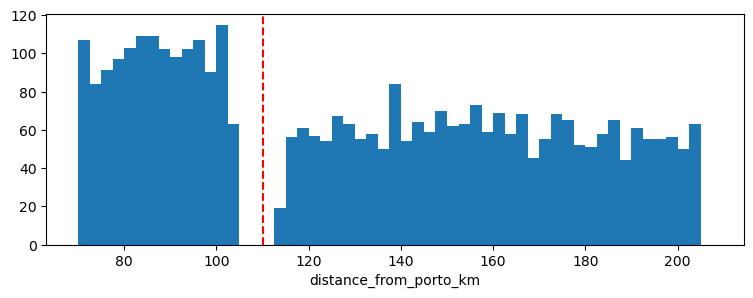

In [2]:
plt.figure(figsize=(9, 3))
plt.hist(df['distance_from_porto_km'], bins=np.arange(70, 210, 2.5))
plt.axvline(110, color='red', ls='--')
plt.xlabel('distance_from_porto_km')
plt.show()

In [3]:
df['group'] = np.where(df['distance_from_porto_km'] < 110, 'near', 'far')
t = df.pivot_table(index='group', columns='treatment', values='harvest_success', aggfunc='mean')
t['diff'] = t['treatment'] - t['control']
t

treatment,control,treatment,diff
group,,,
far,0.321429,0.314433,-0.006996
near,0.253041,0.250000,-0.003041


In [4]:
pd.crosstab(df['group'], df['treatment'])

treatment,control,treatment
group,,
far,420,1746
near,1233,144


Control wins in both groups (near 25.3% vs 25.0%, far 32.1% vs 31.4%).

Treatment was used mostly on far plots (81% of them vs 10% of near ones), and far plots do better anyway, so pooling makes treatment look better.

Other columns, groups where control wins:

In [5]:
for c in ['trellis_system', 'vineyard_age_group', 'cooperative', 'grape_variety',
          'organic_certified', 'harvest_month', 'slope_aspect']:
    r = df.pivot_table(index=c, columns='treatment', values='harvest_success', aggfunc='mean')
    print(c, (r['treatment'] < r['control']).sum(), '/', len(r))

trellis_system 0 / 3
vineyard_age_group 0 / 3
cooperative 3 / 12
grape_variety 0 / 3
organic_certified 0 / 2
harvest_month 0 / 2
slope_aspect 1 / 4
